# Ajwa vs Medjool: CNN Classifier

## Model Strategy

| Decision | Choice | Why |
|---|---|---|
| **Resizing** | **128 x 128 x 3** (RGB, pixels scaled to 0-1) | Source PNGs are multi-megapixel (~2.5 MB each) and vary in size. 128 px is small enough to train fast on 200 images, yet large enough that Medjool wrinkles still show as texture. |
| **Convolution** | **4 blocks**, 3x3 kernels, filters **32 -> 64 -> 128 -> 128**, ReLU | Early blocks (32) catch edges and colour; middle blocks (64) catch wrinkle texture vs smooth skin; deeper blocks (128) combine these into whole-date shape and size. |
| **Pooling** | **MaxPool 2x2** after each block (128 -> 64 -> 32 -> 16 -> 8) | Halves height/width each time, keeps the strongest activations (wrinkle edges), and gives some position tolerance. |
| **Output** | **Flatten -> Dense(64, ReLU) -> Dropout(0.5) -> Dense(1, sigmoid)** | Flatten turns the 8x8x128 feature maps into a vector; the sigmoid gives P(Medjool). Above 0.5 = Medjool, else Ajwa. |

**Layer sequence**

```
Input (128x128x3)
  -> Augmentation (flip, rotate, zoom, brightness; training only)
  -> Conv 32 -> MaxPool
  -> Conv 64 -> MaxPool
  -> Conv 128 -> MaxPool
  -> Conv 128 -> MaxPool          (8x8x128)
  -> Flatten (8192)
  -> Dense 64 + Dropout 0.5
  -> Dense 1 (sigmoid): Ajwa (0) / Medjool (1)
```

**Risks we planned for**
- *Data leakage:* each date has 5 photos, and the background-removed images are copies of the originals. A random image-level split would put near-identical photos in both train and test and inflate accuracy. We split **by fruit group** instead.
- *Tiny dataset:* augmentation + dropout + early stopping to limit overfitting.

---
## Working Model

In [1]:
!pip -q install tensorflow scikit-learn pillow requests
import os, glob, zipfile, io, random, requests
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from PIL import Image
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
IMG_SIZE = 128

## 1. Initialize the dataset


In [2]:
URL = "https://archive.ics.uci.edu/static/public/879/ajwa+or+medjool.zip"
DATA_DIR = "ajwa_medjool"
if not os.path.exists(DATA_DIR):
    r = requests.get(URL, timeout=600); r.raise_for_status()
    zipfile.ZipFile(io.BytesIO(r.content)).extractall(DATA_DIR)
    # the outer zip may contain another zip
    for z in glob.glob(f"{DATA_DIR}/**/*.zip", recursive=True):
        zipfile.ZipFile(z).extractall(os.path.dirname(z))

files = sorted(glob.glob(f"{DATA_DIR}/**/*.png", recursive=True) + glob.glob(f"{DATA_DIR}/**/*.jpg", recursive=True))
print("images found:", len(files))
from collections import Counter
print(Counter(os.path.dirname(f) for f in files))

images found: 200
Counter({'ajwa_medjool\\ajwa+or+medjool\\Ajwa': 100, 'ajwa_medjool\\ajwa+or+medjool\\Medjool': 100})


In [3]:
FOLDER_FILTER = None   # e.g. "original" or "without" to keep only folders whose path contains this text

def label_of(path):
    folder = os.path.basename(os.path.dirname(path)).lower()
    if folder == "medjool": return 1
    if folder == "ajwa": return 0
    return None

def load(path):
    img = Image.open(path)
    if img.mode in ("RGBA", "LA", "P"):          # background-removed PNGs: paste on white
        img = img.convert("RGBA")
        bg = Image.new("RGBA", img.size, (255, 255, 255, 255))
        img = Image.alpha_composite(bg, img)
    img = img.convert("RGB").resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR)
    return np.asarray(img, dtype=np.uint8)

paths = [f for f in files if label_of(f) is not None and (FOLDER_FILTER is None or FOLDER_FILTER.lower() in f.lower())]

# Group id: every 5 consecutive files (sorted by timestamp name) in a folder = 5 photos of one date.
# This is a heuristic; it keeps near-duplicate photos on the same side of the split.
groups, by_folder = [], {}
for p in paths:
    by_folder.setdefault(os.path.dirname(p), []).append(p)
gid = {}
for folder, lst in by_folder.items():
    for i, p in enumerate(sorted(lst)):
        gid[p] = f"{folder}:{i // 5}"
# background-removed copies of the same photo should share a group too, so merge by base name if names match
base_groups = {}
for p in paths:
    cls = label_of(p)
    key = (cls, os.path.splitext(os.path.basename(p))[0])
    base_groups.setdefault(key, gid[p])
groups = [base_groups[(label_of(p), os.path.splitext(os.path.basename(p))[0])] for p in paths]

X = np.stack([load(p) for p in paths])
y = np.array([label_of(p) for p in paths])
groups = np.array(groups)
print(X.shape, "Ajwa:", (y == 0).sum(), "Medjool:", (y == 1).sum(), "| groups:", len(set(groups)))

(200, 128, 128, 3) Ajwa: 100 Medjool: 100 | groups: 40


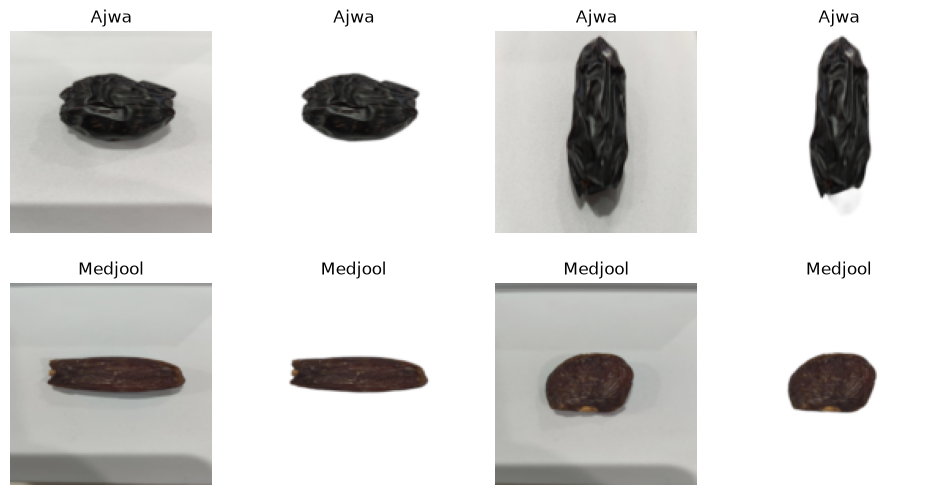

In [4]:
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for row, cls in enumerate([0, 1]):
    idx = np.where(y == cls)[0][:4]
    for a, i in zip(ax[row], idx):
        a.imshow(X[i]); a.axis("off"); a.set_title(["Ajwa", "Medjool"][cls])
plt.show()

### Group-aware train / validation / test split (~72 / 14 / 14, classes balanced)

In [5]:
from sklearn.model_selection import StratifiedGroupKFold

sgkf = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=SEED)
folds = [f[1] for f in sgkf.split(X, y, groups)]   # 7 disjoint chunks of whole groups
te = folds[0]                                       # ~14% test
va = folds[1]                                       # ~14% validation
tr = np.concatenate(folds[2:])                      # ~72% train

assert not set(groups[tr]) & set(groups[te]) and not set(groups[tr]) & set(groups[va])
for name, idx in [("train", tr), ("val", va), ("test", te)]:
    print(f"{name:5s} n={len(idx):3d}  Ajwa={np.sum(y[idx]==0):3d}  Medjool={np.sum(y[idx]==1):3d}")

BATCH = 16
def ds(idx, train=False):
    d = tf.data.Dataset.from_tensor_slices((X[idx], y[idx].astype("float32")))
    if train: d = d.shuffle(len(idx), seed=SEED)
    return d.batch(BATCH).prefetch(tf.data.AUTOTUNE)
train_ds, val_ds, test_ds = ds(tr, True), ds(va), ds(te)

train n=140  Ajwa= 70  Medjool= 70
val   n= 30  Ajwa= 14  Medjool= 16
test  n= 30  Ajwa= 16  Medjool= 14


## 2. Build the CNN 

In [6]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.15),
    layers.RandomBrightness(0.15, value_range=(0, 1)),
], name="augmentation")

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding="same", activation="relu")(x)
    return layers.MaxPooling2D(2)(x)

inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
x = layers.Rescaling(1 / 255.)(inputs)
x = augment(x)                       # active only during training
for f in (32, 64, 128, 128):
    x = conv_block(x, f)
x = layers.Flatten()(x)
x = layers.Dense(64, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)   # P(Medjool)

model = keras.Model(inputs, outputs, name="date_cnn")
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
model.summary()

Model: "date_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       524,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 765,249 (2.92 MB)

 Trainable params: 765,249 (2.92 MB)

 Non-trainable params: 0 (0.00 B)

## 3. Train

Epoch 1/60


c:\Users\Admin\anaconda3\envs\team_pipeline\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


9/9 - 5s - 551ms/step - accuracy: 0.5143 - loss: 0.7082 - val_accuracy: 0.5333 - val_loss: 0.6916 - learning_rate: 0.0010
Epoch 2/60
9/9 - 1s - 158ms/step - accuracy: 0.4714 - loss: 0.6945 - val_accuracy: 0.4667 - val_loss: 0.6930 - learning_rate: 0.0010
Epoch 3/60
9/9 - 1s - 166ms/step - accuracy: 0.5143 - loss: 0.6940 - val_accuracy: 0.5333 - val_loss: 0.6927 - learning_rate: 0.0010
Epoch 4/60
9/9 - 1s - 149ms/step - accuracy: 0.5214 - loss: 0.6923 - val_accuracy: 0.5333 - val_loss: 0.6918 - learning_rate: 0.0010
Epoch 5/60
9/9 - 2s - 167ms/step - accuracy: 0.4714 - loss: 0.6960 - val_accuracy: 0.5333 - val_loss: 0.6878 - learning_rate: 0.0010
Epoch 6/60
9/9 - 1s - 162ms/step - accuracy: 0.6000 - loss: 0.6781 - val_accuracy: 0.5333 - val_loss: 0.6287 - learning_rate: 0.0010
Epoch 7/60
9/9 - 1s - 147ms/step - accuracy: 0.7643 - loss: 0.5502 - val_accuracy: 1.0000 - val_loss: 0.1844 - learning_rate: 0.0010
Epoch 8/60
9/9 - 1s - 146ms/step - accuracy: 0.8500 - loss: 0.4264 - val_accurac

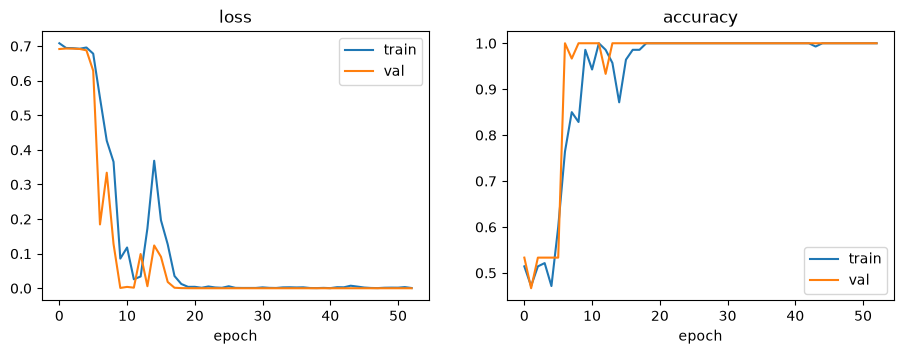

In [7]:
cbs = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4),
]
history = model.fit(train_ds, validation_data=val_ds, epochs=60, callbacks=cbs, verbose=2)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, m in zip(ax, ["loss", "accuracy"]):
    a.plot(history.history[m], label="train"); a.plot(history.history["val_" + m], label="val")
    a.set_title(m); a.set_xlabel("epoch"); a.legend()
plt.show()

## 4. Evaluate on the held-out test set

TEST accuracy: 1.000   (loss 0.000)
              precision    recall  f1-score   support

        Ajwa       1.00      1.00      1.00        16
     Medjool       1.00      1.00      1.00        14

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



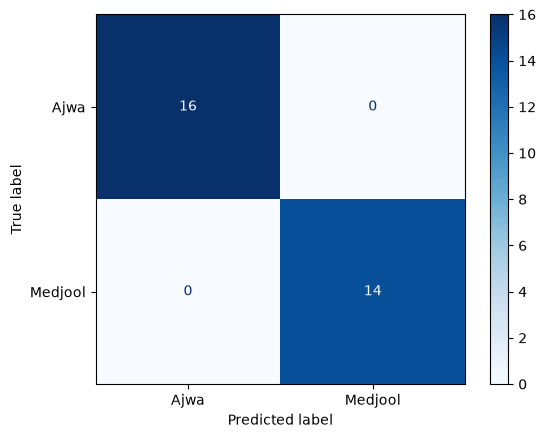

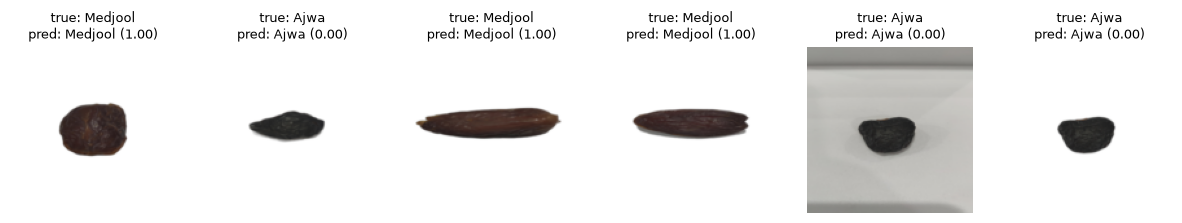

In [8]:
loss, acc = model.evaluate(test_ds, verbose=0)
print(f"TEST accuracy: {acc:.3f}   (loss {loss:.3f})")

probs = model.predict(X[te], verbose=0).ravel()
pred = (probs > 0.5).astype(int)
print(classification_report(y[te], pred, labels=[0, 1], target_names=["Ajwa", "Medjool"], zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y[te], pred, labels=[0, 1]), display_labels=["Ajwa", "Medjool"]).plot(cmap="Blues")
plt.show()

# a few predictions
fig, ax = plt.subplots(1, 6, figsize=(15, 3))
for a, i in zip(ax, np.random.choice(len(te), 6, replace=False)):
    a.imshow(X[te][i]); a.axis("off")
    a.set_title(f"true: {['Ajwa','Medjool'][y[te][i]]}\npred: {['Ajwa','Medjool'][pred[i]]} ({probs[i]:.2f})", fontsize=9)
plt.show()

### Notes for discussion
- With only ~30 test images, one mistake moves accuracy by about 3 points. Treat the number as a rough estimate; re-run with different `SEED` values or use cross-validation for a steadier figure.
- Ajwa and Medjool differ a lot in size and skin, so high accuracy is expected. Check whether the model is relying on the background or lighting rather than the date: try `FOLDER_FILTER` to train on only the background-removed images.